# 5. EDA:

Thiết lập môi trường & Kiểm tra tính toàn vẹn dữ liệu Sổ cái:

In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec
import seaborn as sns
from plotnine import *
import warnings

# Tắt cảnh báo
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid", palette="muted")

FILE_PATH = r"E:\PTDLTKTKT\general_ledger_large.csv"

# 1. Đọc dữ liệu với Pandas & Polars
gl_pd = pd.read_csv(FILE_PATH, parse_dates=["entry_date"])
gl_pl = pl.read_csv(FILE_PATH, try_parse_dates=True)

print(f"Kích thước dữ liệu: {gl_pd.shape[0]:,} dòng giao dịch | {gl_pd['entry_id'].nunique():,} bút toán (Journal Entries)")

# 2. Kiểm tra tính toàn vẹn kế toán
total_debit = gl_pd["debit"].sum()
total_credit = gl_pd["credit"].sum()
imbalanced_jes = (
    gl_pd.groupby("entry_id")[["debit", "credit"]]
    .sum()
    .assign(diff=lambda df: (df["debit"] - df["credit"]).round(2))
    .query("diff != 0")
)

print("-" * 65)
print(f"Tổng phát sinh Nợ (Total Debit) : ${total_debit:,.2f}")
print(f"Tổng phát sinh Có (Total Credit): ${total_credit:,.2f}")
print(f"Chênh lệch toàn Sổ cái          : ${(total_debit - total_credit):,.2f}")
print(f"Số bút toán (JE) bị lệch Nợ/Có  : {len(imbalanced_jes)} bút toán")
print("-" * 65)

display(gl_pd.head())

Kích thước dữ liệu: 1,504 dòng giao dịch | 752 bút toán (Journal Entries)
-----------------------------------------------------------------
Tổng phát sinh Nợ (Total Debit) : $3,041,136.98
Tổng phát sinh Có (Total Credit): $3,041,136.98
Chênh lệch toàn Sổ cái          : $0.00
Số bút toán (JE) bị lệch Nợ/Có  : 0 bút toán
-----------------------------------------------------------------


,entry_id,entry_date,account,debit,credit,department,posted_by
0,JE3253,2025-01-01,Cost of Goods Sold,1231.76,0.00,Operations,mchen
1,JE3253,2025-01-01,Inventory,0.00,1231.76,Operations,mchen
2,JE3413,2025-01-01,Accounts Receivable,3024.76,0.00,Sales,agarcia
3,JE3413,2025-01-01,Sales Revenue,0.00,3024.76,Sales,agarcia
4,JE3476,2025-01-01,Cash,4476.03,0.00,Sales,rpatel


## 5.1. Thống kê tần suất biến định danh:

Tần suất số dòng phát sinh theo phòng ban:

In [2]:
# Pandas:

dept_summary_pd = (
    gl_pd.groupby("department")
    .agg(
        total_lines=("entry_id", "count"),
        unique_jes=("entry_id", "nunique"),
        total_debit=("debit", "sum")
    )
    .assign(
        line_pct=lambda df: (df["total_lines"] / len(gl_pd) * 100).round(2),
        debit_pct=lambda df: (df["total_debit"] / df["total_debit"].sum() * 100).round(2)
    )
    .sort_values(by="total_lines", ascending=False)
)

print("Bảng tổng hợp quy mô giao dịch theo Phòng ban (Pandas):")
display(dept_summary_pd.style.format({
    "total_lines": "{:,}",
    "unique_jes": "{:,}",
    "total_debit": "${:,.2f}",
    "line_pct": "{:.2f}%",
    "debit_pct": "{:.2f}%"
}))

Bảng tổng hợp quy mô giao dịch theo Phòng ban (Pandas):


,total_lines,unique_jes,total_debit,line_pct,debit_pct
department,,,,,
Operations,700,350,"$913,003.72",46.54%,30.02%
Sales,572,286,"$1,635,771.29",38.03%,53.79%
HR,132,66,"$458,950.41",8.78%,15.09%
Finance,100,50,"$33,411.56",6.65%,1.10%


In [3]:
# Polars:

dept_summary_pl = (
    gl_pl.group_by("department")
    .agg([
        pl.len().alias("total_lines"),
        pl.col("entry_id").n_unique().alias("unique_jes"),
        pl.col("debit").sum().round(2).alias("total_debit")
    ])
    .with_columns([
        (pl.col("total_lines") / pl.sum("total_lines") * 100).round(2).alias("line_pct (%)")
    ])
    .sort("total_lines", descending=True)
)
print("\nBảng tổng hợp quy mô giao dịch theo Phòng ban (Polars):")
display(dept_summary_pl)


Bảng tổng hợp quy mô giao dịch theo Phòng ban (Polars):


department,total_lines,unique_jes,total_debit,line_pct (%)
str,u32,u32,f64,f64
"""Operations""",700,350,913003.72,46.54
"""Sales""",572,286,1.6358e6,38.03
"""HR""",132,66,458950.41,8.78
"""Finance""",100,50,33411.56,6.65


## 5.2. Đo lường Xu hướng tập trung, Độ phân tán & Hình dáng phân phối:

Tính Mean, Median, Mode, Độ lệch chuẩn (Std), Phương sai (Variance), Khoảng tứ phân vị (IQR), Hệ số biến thiên (CV), Skewness (Độ lệch) và Kurtosis (Độ nhọn).

In [4]:
# Lọc các dòng phát sinh Nợ (Debit > 0)
debit_pd = gl_pd.loc[gl_pd["debit"] > 0, "debit"]
debit_pl = gl_pl.filter(pl.col("debit") > 0).get_column("debit")

def get_financial_stats(series: pd.Series) -> pd.DataFrame:

    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    mean_val = series.mean()
    std_val = series.std()
    
    stats = {
        "Count (Số giao dịch)": len(series),
        "Mean (Trung bình)": f"${mean_val:,.2f}",
        "Median (Trung vị - Q2)": f"${series.median():,.2f}",
        "Mode (Yếu vị)": f"${series.mode().iloc[0]:,.2f}",
        "Std Dev (Độ lệch chuẩn)": f"${std_val:,.2f}",
        "Variance (Phương sai)": f"{series.var():,.2f}",
        "IQR (Khoảng tứ phân vị)": f"${iqr:,.2f}",
        "Min (Nhỏ nhất)": f"${series.min():,.2f}",
        "Max (Lớn nhất)": f"${series.max():,.2f}",
        "CV (Hệ số biến thiên)": f"{std_val / mean_val:.4f}",
        "Skewness (Độ lệch)": f"{series.skew():.4f} (Lệch phải rất mạnh)",
        "Kurtosis (Độ nhọn)": f"{series.kurt():.4f} (Phân phối đuôi béo/Có cực trị)"
    }
    return pd.DataFrame.from_dict(stats, orient="index", columns=["Giá trị thống kê"])

print("BẢNG THỐNG KÊ MÔ TẢ CHI TIẾT PHÁT SINH NỢ (DEBIT > 0):")
display(get_financial_stats(debit_pd))

BẢNG THỐNG KÊ MÔ TẢ CHI TIẾT PHÁT SINH NỢ (DEBIT > 0):


,Giá trị thống kê
Count (Số giao dịch),752
Mean (Trung bình),"$4,044.07"
Median (Trung vị - Q2),"$2,457.11"
Mode (Yếu vị),"$1,739.52"
Std Dev (Độ lệch chuẩn),"$11,497.58"
Variance (Phương sai),"132,194,329.96"
IQR (Khoảng tứ phân vị),"$2,576.86"
Min (Nhỏ nhất),$197.71
Max (Lớn nhất),"$176,500.00"
CV (Hệ số biến thiên),2.8431


## 5.3. Trực quan hóa Phân phối:

Chạy Histogram và Boxplot toàn dải.
Lọc và vẽ Histogram phóng to cho các giao dịch dưới 10.000 USD (chiếm 97,2% tổng số giao dịch).

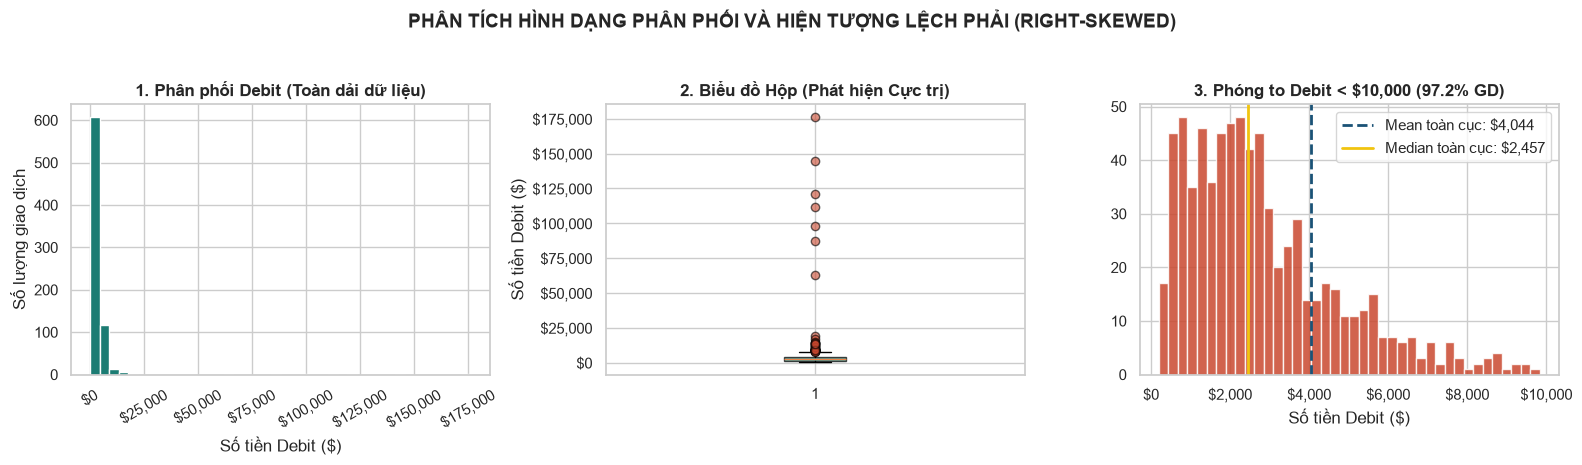

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
currency_fmt = ticker.StrMethodFormatter('${x:,.0f}')

# 1. Histogram toàn dải
axes[0].hist(debit_pd, bins=40, color="#1c7c73", edgecolor="white")
axes[0].set_title("1. Phân phối Debit (Toàn dải dữ liệu)", fontweight="bold")
axes[0].set_xlabel("Số tiền Debit ($)")
axes[0].set_ylabel("Số lượng giao dịch")
axes[0].xaxis.set_major_formatter(currency_fmt)
axes[0].tick_params(axis='x', rotation=30)

# 2. Boxplot toàn dải
axes[1].boxplot(
    debit_pd, 
    orientation="vertical", 
    patch_artist=True,
    boxprops=dict(facecolor="#1c7c73", alpha=0.7),
    flierprops=dict(marker='o', markerfacecolor='#c9482f', markersize=6, alpha=0.6)
)
axes[1].set_title("2. Biểu đồ Hộp (Phát hiện Cực trị)", fontweight="bold")
axes[1].set_ylabel("Số tiền Debit ($)")
axes[1].yaxis.set_major_formatter(currency_fmt)

# 3. Histogram phóng to (< $10,000) kèm đường so sánh Mean vs Median
zoomed_pd = debit_pd[debit_pd < 10000]
axes[2].hist(zoomed_pd, bins=40, color="#c9482f", edgecolor="white", alpha=0.85)
axes[2].axvline(debit_pd.mean(), color="#1a5276", linestyle="--", linewidth=2, label=f"Mean toàn cục: ${debit_pd.mean():,.0f}")
axes[2].axvline(debit_pd.median(), color="#f1c40f", linestyle="-", linewidth=2, label=f"Median toàn cục: ${debit_pd.median():,.0f}")
axes[2].set_title(f"3. Phóng to Debit < $10,000 ({len(zoomed_pd)/len(debit_pd):.1%} GD)", fontweight="bold")
axes[2].set_xlabel("Số tiền Debit ($)")
axes[2].xaxis.set_major_formatter(currency_fmt)
axes[2].legend(frameon=True, facecolor="white")

plt.suptitle("PHÂN TÍCH HÌNH DẠNG PHÂN PHỐI VÀ HIỆN TƯỢNG LỆCH PHẢI (RIGHT-SKEWED)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 5.4. Phát hiện Ngoại lai & Đánh giá Rủi ro Kiểm toán:

So sánh trực tiếp Z-score và IQR, tự động gắn cờ "Rủi ro cuối tuần" - Weekend Posting Flag để phục vụ kiểm toán.

In [ ]:
# Chuẩn bị bảng phân tích Outlier chuyên sâu
debit_df = gl_pd[gl_pd["debit"] > 0].copy()

# Tính Z-score
mean_val, std_val = debit_df["debit"].mean(), debit_df["debit"].std()
debit_df["z_score"] = (debit_df["debit"] - mean_val) / std_val

# Tính ngưỡng IQR
q1, q3 = debit_df["debit"].quantile([0.25, 0.75])
iqr = q3 - q1
iqr_upper_bound = q3 + 1.5 * iqr

# Gắn cờ phân loại và trích xuất thông tin ngày trong tuần
debit_df["flag_zscore"] = debit_df["z_score"].abs() > 3
debit_df["flag_iqr"] = debit_df["debit"] > iqr_upper_bound
debit_df["day_of_week"] = debit_df["entry_date"].dt.day_name()
debit_df["is_weekend"] = debit_df["day_of_week"].isin(["Saturday", "Sunday"])

# Lấy giao của hai danh sách (Bị gắn cờ bởi Z-score và IQR)
debit_df["flag_both"] = debit_df["flag_zscore"] & debit_df["flag_iqr"]
overlap_count = debit_df["flag_both"].sum()

print(f"Ngưỡng cắt trên phương pháp IQR (Q3 + 1.5*IQR): ${iqr_upper_bound:,.2f}")
print(f"Số giao dịch bị gắn cờ bởi IQR           : {debit_df['flag_iqr'].sum()} giao dịch (Chiếm {debit_df['flag_iqr'].mean():.1%})")
print(f"Số giao dịch bị gắn cờ bởi Z-score       : {debit_df['flag_zscore'].sum()} giao dịch (Chiếm {debit_df['flag_zscore'].mean():.1%})")
print(f"Số giao dịch trùng khớp (Cả IQR & Z-score): {overlap_count} giao dịch\n")

# Hiển thị chi tiết các giao dịch Z-score (kết hợp xem có nằm trong IQR không)
outliers_z = debit_df[debit_df["flag_zscore"]].sort_values(by="debit", ascending=False)
cols_to_show = ["entry_id", "entry_date", "day_of_week", "is_weekend", "account", "department", "posted_by", "debit", "z_score", "flag_both"]

print("DANH SÁCH CÁC BÚT TOÁN BẤT THƯỜNG NGHIÊM TRỌNG (|Z-SCORE| > 3) CẦN KIỂM TOÁN:")
display(
    outliers_z[cols_to_show]
    .style.format({"debit": "${:,.2f}", "z_score": "{:.2f}", "entry_date": lambda x: x.strftime('%Y-%m-%d')})
    .highlight_max(subset=["debit"], color="#911d13")
    .map(lambda v: 'background-color: #fcf3cf; font-weight: bold; color: #b03a2e' if v is True else '', subset=['is_weekend'])
)

# Thống kê người nhập liệu (posted_by) trong nhóm bất thường
print("\nTần suất nhân viên thực hiện các bút toán ngoại lai (Z-score > 3):")
print(outliers_z["posted_by"].value_counts().to_frame(name="outlier_count"))

Ngưỡng cắt trên phương pháp IQR (Q3 + 1.5*IQR): $7,827.10
Số giao dịch bị gắn cờ bởi IQR           : 38 giao dịch (Chiếm 5.1%)
Số giao dịch bị gắn cờ bởi Z-score       : 7 giao dịch (Chiếm 0.9%)
Số giao dịch trùng khớp (Cả IQR & Z-score): 7 giao dịch

DANH SÁCH CÁC BÚT TOÁN BẤT THƯỜNG NGHIÊM TRỌNG (|Z-SCORE| > 3) CẦN KIỂM TOÁN:


,entry_id,entry_date,day_of_week,is_weekend,account,department,posted_by,debit,z_score,flag_both
1002,JE3903,2025-08-30,Saturday,True,Accounts Receivable,Sales,dwilson,"$176,500.00",15.00,True
322,JE3900,2025-03-14,Friday,False,Accounts Receivable,Sales,dwilson,"$145,000.00",12.26,True
1466,JE3906,2025-12-24,Wednesday,False,Cash,Sales,mchen,"$121,000.00",10.17,True
668,JE3902,2025-06-09,Monday,False,Cost of Goods Sold,Operations,dwilson,"$112,000.00",9.39,True
458,JE3901,2025-04-22,Tuesday,False,Cash,Sales,ktaylor,"$98,000.00",8.17,True
1222,JE3904,2025-11-02,Sunday,True,Salaries Expense,HR,dwilson,"$87,000.00",7.22,True
1068,JE3905,2025-09-19,Friday,False,Accounts Payable,Operations,ktaylor,"$63,000.00",5.13,True



Tần suất nhân viên thực hiện các bút toán ngoại lai (Z-score > 3):
           outlier_count
posted_by               
dwilson                4
ktaylor                2
mchen                  1


Qua bảng phân tích trên, nhân viên dwilson xuất hiện tới 4/7 giao dịch bất thường lớn nhất (bao gồm cả 2 giao dịch vào ngày Thứ Bảy JE3903 và Chủ Nhật JE3904). Trong kiểm toán nội bộ, sự kết hợp giữa Số tiền cực lớn + Nhập liệu cuối tuần + Tập trung vào 1 cá nhân là dấu hiệu rủi ro gian lận (Red Flag) rất cao cần kiểm tra chứng từ gốc ngay lập tức.

## 5.5. Phân tích nhóm theo bộ phận:

So sánh đặc điểm giao dịch giữa 4 bộ phận: Operations, Sales, Finance, HR. Bổ sung thêm cột Tổng tiền và IQR theo từng bộ phận để thấy sự khác biệt giữa biến động chịu ảnh hưởng ngoại lai - CV và biến động nội tại - IQR.

In [8]:
grouped_dept = (
    debit_df.groupby("department")["debit"]
    .agg(
        Count="count",
        Total_Amount="sum",
        Mean="mean",
        Median="median",
        Std="std",
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
    )
    .assign(
        CV=lambda df: df["Std"] / df["Mean"],
        Skewness=debit_df.groupby("department")["debit"].skew()
    )
    .sort_values(by="Total_Amount", ascending=False)
)

print("BẢNG SO SÁNH ĐẶC ĐIỂM GIAO DỊCH ĐA CHIỀU GIỮA CÁC PHÒNG BAN:")
display(grouped_dept.style.format({
    "Count": "{:,}",
    "Total_Amount": "${:,.2f}",
    "Mean": "${:,.2f}",
    "Median": "${:,.2f}",
    "Std": "${:,.2f}",
    "IQR": "${:,.2f}",
    "CV": "{:.2f}",
    "Skewness": "{:.2f}"
}).background_gradient(subset=["CV"], cmap="OrRd"))

BẢNG SO SÁNH ĐẶC ĐIỂM GIAO DỊCH ĐA CHIỀU GIỮA CÁC PHÒNG BAN:


,Count,Total_Amount,Mean,Median,Std,IQR,CV,Skewness
department,,,,,,,,
Sales,286,"$1,635,771.29","$5,719.48","$3,184.82","$16,080.36","$2,683.00",2.81,8.50
Operations,350,"$913,003.72","$2,608.58","$1,987.36","$6,825.53","$1,467.44",2.62,13.86
HR,66,"$458,950.41","$6,953.79","$5,534.10","$10,128.61","$2,368.77",1.46,7.82
Finance,50,"$33,411.56",$668.23,$657.43,$253.99,$318.68,0.38,0.25


# 6. Data Visualization for Accounting:

## 6.1. Phản ánh danh mục tài khoản:

Bổ sung cột "account_type" (Asset, Liability, Expense, Contra-Asset, Revenue); kiểm tra mapping tài khoản và sắp xếp giảm dần theo tổng tiền.

Tổng phát sinh nợ theo phòng ban và Tổng phát sinh nợ theo 12 tháng trong năm tài chính.

In [9]:
account_type_map = {
    "Cash": "Asset", "Accounts Receivable": "Asset", "Inventory": "Asset", "Prepaid Insurance": "Asset",
    "Accumulated Depreciation - Equipment": "Contra-Asset",
    "Accounts Payable": "Liability", "Notes Payable": "Liability",
    "Sales Revenue": "Revenue",
    "Cost of Goods Sold": "Expense", "Salaries Expense": "Expense", "Rent Expense": "Expense",
    "Utilities Expense": "Expense", "Depreciation Expense": "Expense", "Insurance Expense": "Expense",
    "Interest Expense": "Expense",
}

gl_pd["account_type"] = gl_pd["account"].map(account_type_map)
# Kiểm tra xem có tài khoản nào chưa được map hay không
assert gl_pd["account_type"].isna().sum() == 0, "Cảnh báo: Có tài khoản chưa được phân loại!"

debit = gl_pd[gl_pd["debit"] > 0].copy()
debit["month"] = debit["entry_date"].dt.to_period("M").astype(str)

# Sắp xếp giảm dần theo tổng tiền để trực quan hóa tốt hơn
dept_totals = debit.groupby("department", as_index=False)["debit"].sum().sort_values("debit", ascending=False)
monthly = debit.groupby("month", as_index=False)["debit"].sum()
print("Tổng hợp phát sinh Nợ theo Phòng ban:")
display(dept_totals.style.format({"debit": "${:,.2f}"}))
print("\nTổng hợp phát sinh Nợ theo Tháng:")
display(monthly.style.format({"debit": "${:,.2f}"}))

Tổng hợp phát sinh Nợ theo Phòng ban:


,department,debit
3,Sales,"$1,635,771.29"
2,Operations,"$913,003.72"
1,HR,"$458,950.41"
0,Finance,"$33,411.56"



Tổng hợp phát sinh Nợ theo Tháng:


,month,debit
0,2025-01,"$172,341.25"
1,2025-02,"$185,630.06"
2,2025-03,"$334,149.58"
3,2025-04,"$249,734.34"
4,2025-05,"$192,663.53"
5,2025-06,"$270,924.54"
6,2025-07,"$192,653.19"
7,2025-08,"$353,903.51"
8,2025-09,"$217,687.87"
9,2025-10,"$190,253.40"


## 6.2. Biểu đồ so sánh danh mục (Bar Chart) & Biểu đồ xu hướng thời gian (Line Chart):

Vẽ Bar Chart và Line Chart trên cùng 1 khung nhìn báo cáo.

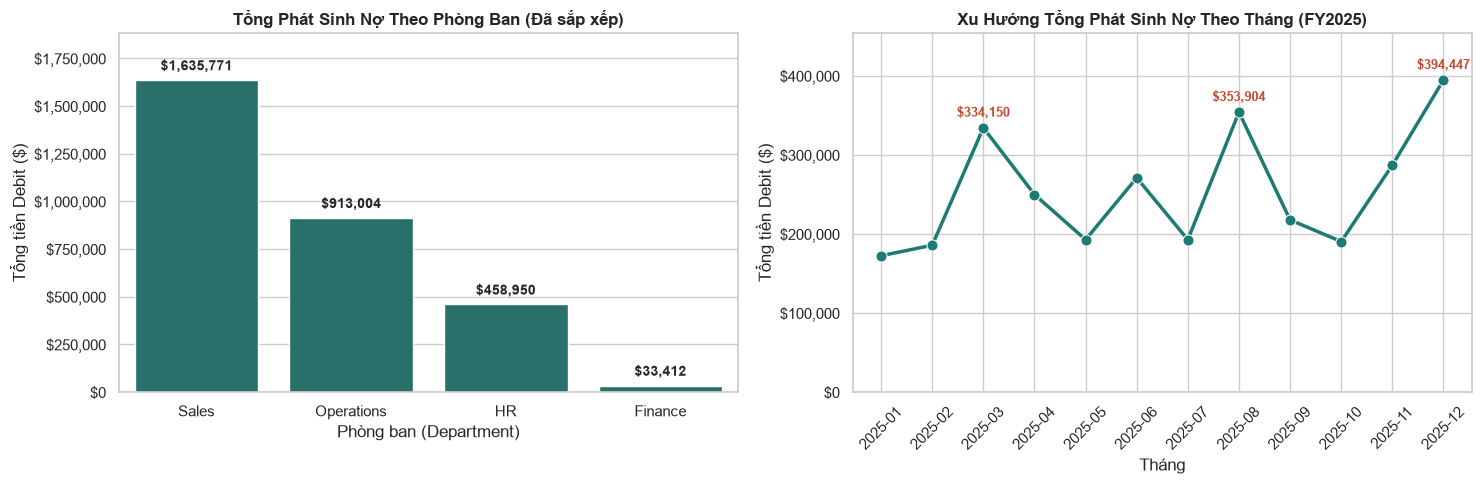

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Bar Chart
bars = sns.barplot(data=dept_totals, x="department", y="debit", color="#1c7c73", ax=axes[0])
axes[0].set_title("Tổng Phát Sinh Nợ Theo Phòng Ban (Đã sắp xếp)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Phòng ban (Department)")
axes[0].set_ylabel("Tổng tiền Debit ($)")
axes[0].yaxis.set_major_formatter(currency_fmt)
axes[0].set_ylim(0, dept_totals["debit"].max() * 1.15)

# Gắn số tiền lên từng cột
for bar in bars.patches:
    height = bar.get_height()
    axes[0].annotate(f'${height:,.0f}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 5), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Line Chart
sns.lineplot(data=monthly, x="month", y="debit", marker="o", linewidth=2.5, markersize=8, color="#1c7c73", ax=axes[1])
axes[1].set_title("Xu Hướng Tổng Phát Sinh Nợ Theo Tháng (FY2025)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tháng")
axes[1].set_ylabel("Tổng tiền Debit ($)")
axes[1].yaxis.set_major_formatter(currency_fmt)
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, monthly["debit"].max() * 1.15)

# Đánh dấu 3 tháng cao điểm (Tháng 3, 8, 12) do ảnh hưởng của Outlier
peak_months = monthly.nlargest(3, "debit")
for _, row in peak_months.iterrows():
    axes[1].annotate(f"${row['debit']:,.0f}", 
                     xy=(row['month'], row['debit']), 
                     xytext=(0, 8), textcoords="offset points",
                     ha='center', fontsize=9, fontweight='bold', color='#c9482f')

plt.tight_layout()
plt.show()

## 6.3. Biểu đồ phân phối (Distribution Plots):

Histogram kèm đường mật độ KDE dưới 10.000 USD.

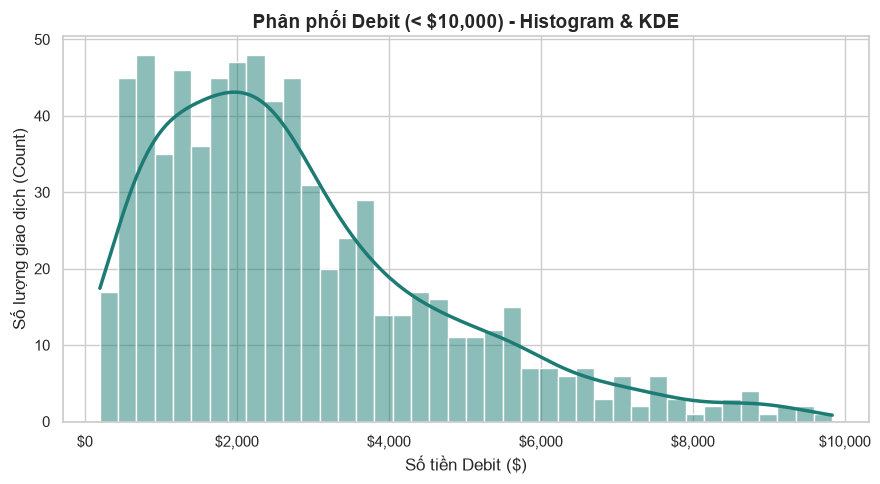

In [11]:
# Định dạng tiền tệ
currency_fmt = ticker.StrMethodFormatter('${x:,.0f}')

# Lọc các giao dịch dưới $10,000
zoomed = debit[debit["debit"] < 10000].copy()

# Biểu đồ Histogram & KDE
plt.figure(figsize=(9, 5))
sns.histplot(
    data=zoomed, x="debit", bins=40, kde=True, 
    color="#1c7c73", edgecolor="white", line_kws={'linewidth': 2.5}
)

plt.title("Phân phối Debit (< $10,000) - Histogram & KDE", fontsize=14, fontweight="bold")
plt.xlabel("Số tiền Debit ($)")
plt.ylabel("Số lượng giao dịch (Count)")
plt.gca().xaxis.set_major_formatter(currency_fmt)

plt.tight_layout()
plt.show()

Kết hợp Violin và Boxplot để vừa thấy mật độ vừa thấy trung vị vừa ghi trực tiếp mã entry_id lên các điểm ngoại lai trên Scatter Plot.

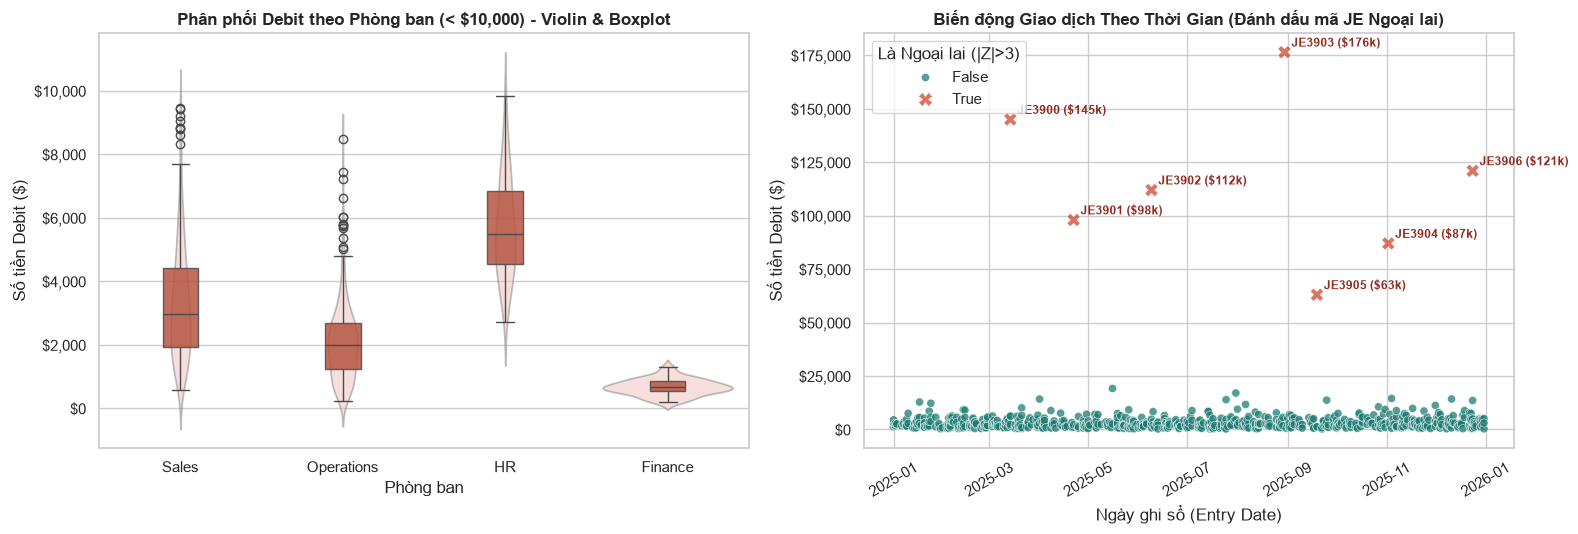

In [12]:
zoomed = debit[debit["debit"] < 10000].copy()
debit["z_score"] = (debit["debit"] - debit["debit"].mean()) / debit["debit"].std()
debit["is_outlier"] = debit["z_score"].abs() > 3

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. Kết hợp Violin Plot + Boxplot bên trong
sns.violinplot(
    data=zoomed, x="department", y="debit", 
    order=["Sales", "Operations", "HR", "Finance"],
    color="#f5b7b1", inner=None, alpha=0.5, ax=axes[0]
)
sns.boxplot(
    data=zoomed, x="department", y="debit", 
    order=["Sales", "Operations", "HR", "Finance"],
    width=0.22, color="#c9482f", boxprops=dict(alpha=0.85), ax=axes[0]
)
axes[0].set_title("Phân phối Debit theo Phòng ban (< $10,000) - Violin & Boxplot", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Phòng ban")
axes[0].set_ylabel("Số tiền Debit ($)")
axes[0].yaxis.set_major_formatter(currency_fmt)

# 2. Scatter Plot theo thời gian có gắn nhãn Mã bút toán (Entry ID) cho các Outlier
sns.scatterplot(
    data=debit, x="entry_date", y="debit", hue="is_outlier",
    style="is_outlier", size="is_outlier", sizes={True: 90, False: 35},
    palette={True: "#c9482f", False: "#1c7c73"}, alpha=0.75, ax=axes[1]
)
# Ghi chú mã JE lên từng điểm Outlier
for _, row in debit[debit["is_outlier"]].iterrows():
    axes[1].annotate(
        f"{row['entry_id']} (${row['debit']/1000:.0f}k)",
        xy=(row["entry_date"], row["debit"]),
        xytext=(5, 4), textcoords="offset points",
        fontsize=8.5, fontweight="bold", color="#922b21"
    )

axes[1].set_title("Biến động Giao dịch Theo Thời Gian (Đánh dấu mã JE Ngoại lai)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ngày ghi sổ (Entry Date)")
axes[1].set_ylabel("Số tiền Debit ($)")
axes[1].yaxis.set_major_formatter(currency_fmt)
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(title="Là Ngoại lai (|Z|>3)", loc="upper left")

plt.tight_layout()
plt.show()

## 6.4. Ma trận Nhiệt đối xứng Nợ vs Có:

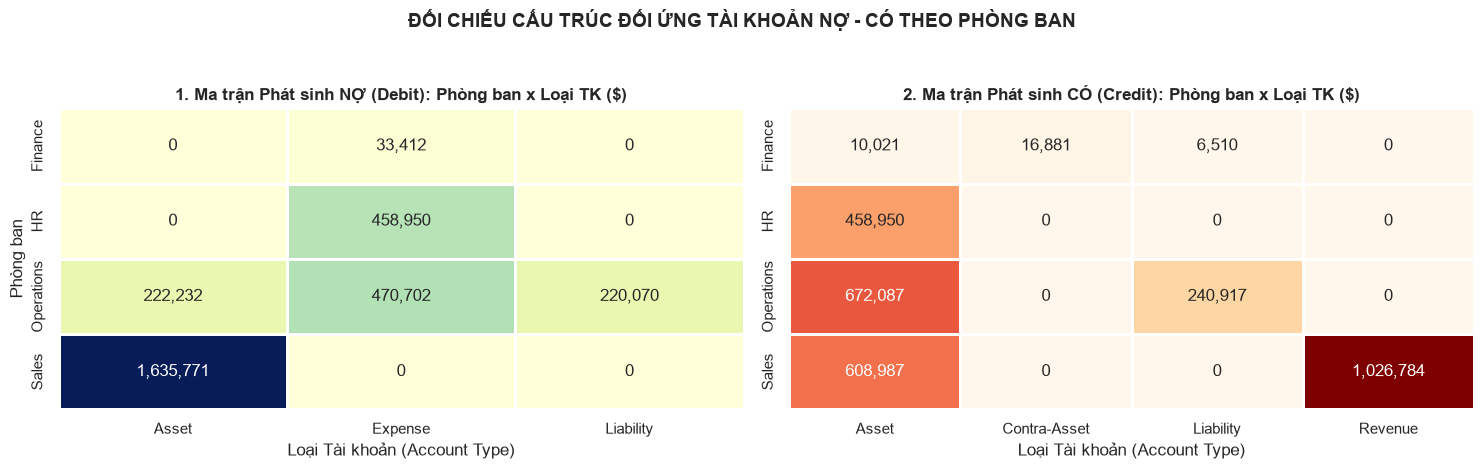

In [13]:
pivot_debit = debit.pivot_table(
    index="department", columns="account_type", values="debit", aggfunc="sum", fill_value=0
)

credit = gl_pd[gl_pd["credit"] > 0].copy()
pivot_credit = credit.pivot_table(
    index="department", columns="account_type", values="credit", aggfunc="sum", fill_value=0
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Heatmap Bên Nợ (Debit)
sns.heatmap(pivot_debit, annot=True, fmt=",.0f", cmap="YlGnBu", cbar=False, linewidths=1, ax=axes[0])
axes[0].set_title("1. Ma trận Phát sinh NỢ (Debit): Phòng ban x Loại TK ($)", fontweight="bold")
axes[0].set_xlabel("Loại Tài khoản (Account Type)")
axes[0].set_ylabel("Phòng ban")

# Heatmap Bên Có (Credit)
sns.heatmap(pivot_credit, annot=True, fmt=",.0f", cmap="OrRd", cbar=False, linewidths=1, ax=axes[1])
axes[1].set_title("2. Ma trận Phát sinh CÓ (Credit): Phòng ban x Loại TK ($)", fontweight="bold")
axes[1].set_xlabel("Loại Tài khoản (Account Type)")
axes[1].set_ylabel("")

plt.suptitle("ĐỐI CHIẾU CẤU TRÚC ĐỐI ỨNG TÀI KHOẢN NỢ - CÓ THEO PHÒNG BAN", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## 6.5. Biểu đồ chia ô nhỏ (Faceting - Small Multiples):

Lưới phân phối phát sinh nợ riêng biệt cho từng bộ phận.

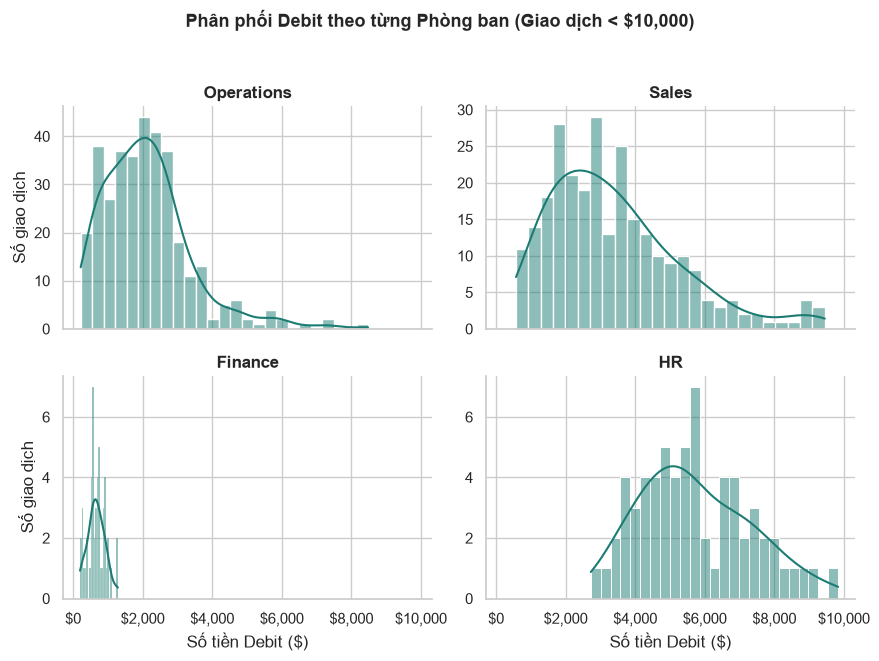

In [14]:
# FacetGrid theo Phòng ban
g = sns.FacetGrid(zoomed, col="department", col_wrap=2, height=3.2, aspect=1.4, sharex=True, sharey=False)
g.map_dataframe(sns.histplot, x="debit", bins=25, kde=True, color="#1c7c73", edgecolor="white")
g.set_titles("{col_name}", fontweight="bold")
g.set_axis_labels("Số tiền Debit ($)", "Số giao dịch")
for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(currency_fmt)
g.figure.suptitle("Phân phối Debit theo từng Phòng ban (Giao dịch < $10,000)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6.6. Dashboard quản trị (Matplotlib GridSpec):

Ghép bảng điều khiển tổng hợp 3 đồ thị (Xu hướng tháng, Tổng theo bộ phận, Phân phối giao dịch).

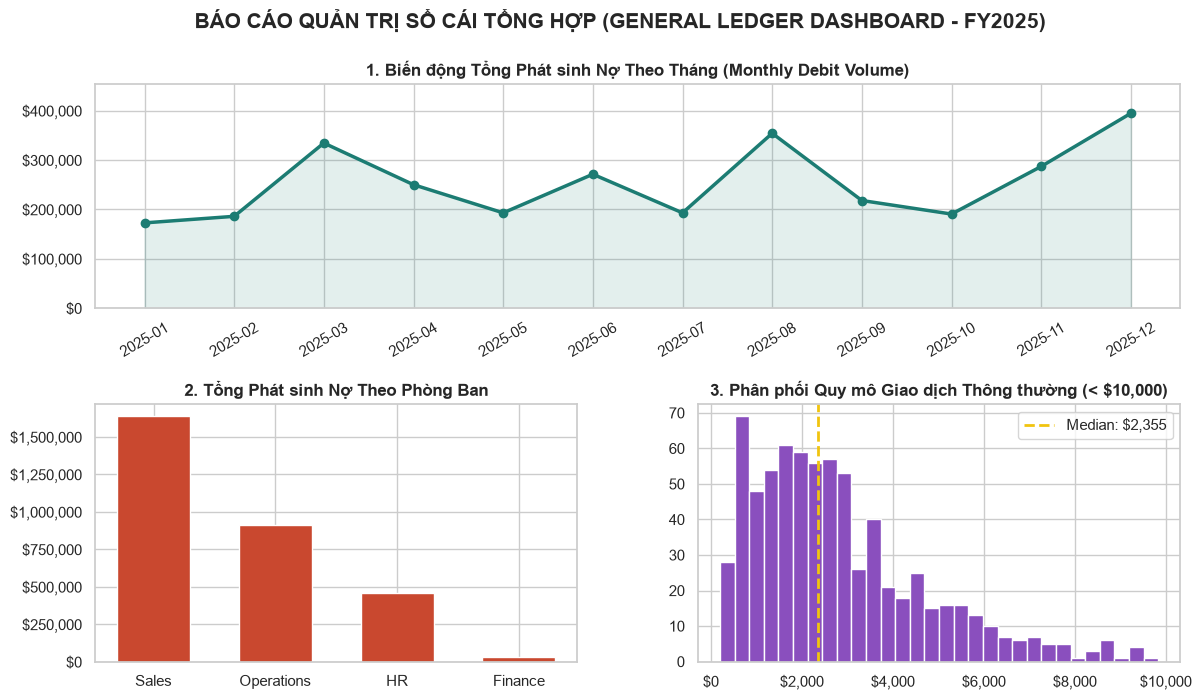

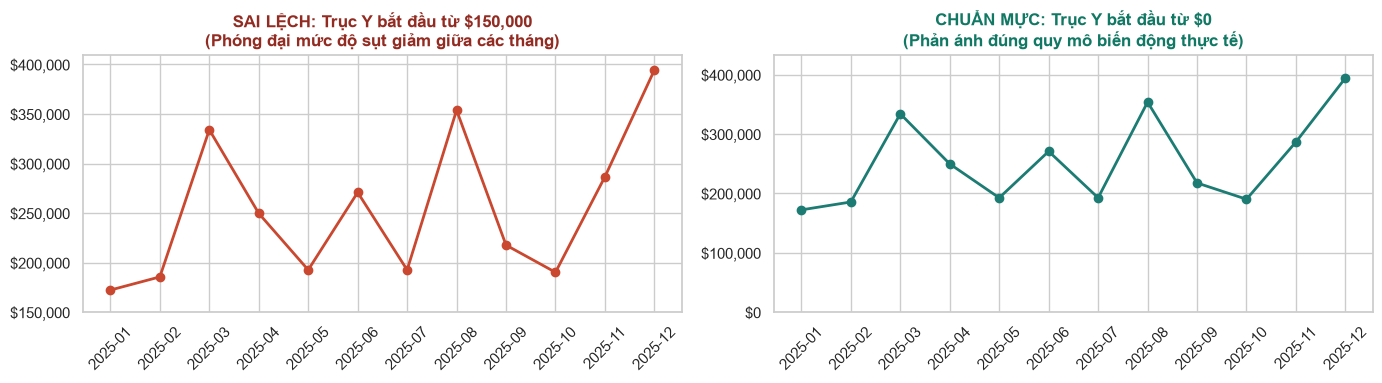

In [15]:
# 1. EXECUTIVE DASHBOARD (MATPLOTLIB GRIDSPEC)
fig = plt.figure(figsize=(14, 7.5))
gs = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1, 1.15], hspace=0.4, wspace=0.25)

# Xu hướng tháng
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(monthly["month"], monthly["debit"], marker="o", linewidth=2.5, color="#1c7c73")
ax1.fill_between(monthly["month"], monthly["debit"], color="#1c7c73", alpha=0.12)
ax1.set_title("1. Biến động Tổng Phát sinh Nợ Theo Tháng (Monthly Debit Volume)", fontweight="bold")
ax1.yaxis.set_major_formatter(currency_fmt)
ax1.set_ylim(0, monthly["debit"].max() * 1.15)
ax1.tick_params(axis="x", rotation=30)

# Tỷ trọng theo phòng ban
ax2 = fig.add_subplot(gs[1, 0])
ax2.bar(dept_totals["department"], dept_totals["debit"], color="#c9482f", edgecolor="white", width=0.6)
ax2.set_title("2. Tổng Phát sinh Nợ Theo Phòng Ban", fontweight="bold")
ax2.yaxis.set_major_formatter(currency_fmt)

# Phân phối chi tiết
ax3 = fig.add_subplot(gs[1, 1])
ax3.hist(zoomed["debit"], bins=30, color="#8a4fbe", edgecolor="white")
ax3.axvline(zoomed["debit"].median(), color="#f1c40f", linestyle="--", linewidth=2, label=f"Median: ${zoomed['debit'].median():,.0f}")
ax3.set_title("3. Phân phối Quy mô Giao dịch Thông thường (< $10,000)", fontweight="bold")
ax3.xaxis.set_major_formatter(currency_fmt)
ax3.legend()

fig.suptitle("BÁO CÁO QUẢN TRỊ SỔ CÁI TỔNG HỢP (GENERAL LEDGER DASHBOARD - FY2025)", fontsize=15, fontweight="bold", y=0.98)
plt.show()

# 2. MINH HỌA NGUYÊN TẮC TRỰC QUAN HÓA: TRỤC Y BỊ CẮT CỤT VS TRỤC Y CHUẨN
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Biểu đồ sai lệch (Cắt trục Y từ $150,000)
axes[0].plot(monthly["month"], monthly["debit"], marker="o", color="#c9482f", linewidth=2)
axes[0].set_ylim(150000, 410000)
axes[0].set_title("SAI LỆCH: Trục Y bắt đầu từ $150,000\n(Phóng đại mức độ sụt giảm giữa các tháng)", fontweight="bold", color="#922b21")
axes[0].yaxis.set_major_formatter(currency_fmt)
axes[0].tick_params(axis="x", rotation=45)

# Biểu đồ trung thực (Trục Y bắt đầu từ $0)
axes[1].plot(monthly["month"], monthly["debit"], marker="o", color="#1c7c73", linewidth=2)
axes[1].set_ylim(0, monthly["debit"].max() * 1.1)
axes[1].set_title("CHUẨN MỰC: Trục Y bắt đầu từ $0\n(Phản ánh đúng quy mô biến động thực tế)", fontweight="bold", color="#117864")
axes[1].yaxis.set_major_formatter(currency_fmt)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()